# データサイエンス実践A 第９講：ヒストグラムとエラーバー
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月6日（金）**

1. 最初に、数値のデータを区間ごとに数えて、分布を見る**ヒストグラム**を学ぶ（AA）。
1. 次に、平均とばらつきを点1つと縦の線1本で表す**エラーバー**を学ぶ（AB）。
1. CES-Alpha の演習「第９講」の `hist_第９講1`、`hist_第９講2`、`hist_描画基礎005`、`errorbar01`〜`errorbar05` を解く。`hist_第９講3`・`hist_第９講4`・`hist_描画基礎006` は発展（AC）。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[AA. ヒストグラム](#AA.-ヒストグラム)**（演習の hist）
- [AA-0 今日の完成形（ヒストグラム）](#AA-0-今日の完成形（ヒストグラム）)
- [AA-1 ヒストグラムの基本：まず手で数えてみる](#AA-1-ヒストグラムの基本：まず手で数えてみる)
- [AA-2 区切りの数](#AA-2-区切りの数)
- [AA-3 色と枠線](#AA-3-色と枠線)
- [AA-4 区切りの範囲](#AA-4-区切りの範囲)
- [AA-5 平均の補助線](#AA-5-平均の補助線)
- [AA-6 2つのグループを重ねる](#AA-6-2つのグループを重ねる)

**[AB. エラーバー](#AB.-エラーバー)**（演習の errorbar）
- [AB-0 今日の完成形（エラーバー）](#AB-0-今日の完成形（エラーバー）)
- [AB-1 平均だけでは分からないこと](#AB-1-平均だけでは分からないこと)
- [AB-2 リストを np.array にする](#AB-2-リストを-np.array-にする)
- [AB-3 平均と標準偏差を求める](#AB-3-平均と標準偏差を求める)
- [AB-4 エラーバーを描く](#AB-4-エラーバーを描く)
- [AB-5 5教科のエラーバー](#AB-5-5教科のエラーバー)
- [AB-6 棒グラフにエラーバーを付ける](#AB-6-棒グラフにエラーバーを付ける)

**[AC. 発展（できる人だけ）](#AC.-発展（できる人だけ）)**
- [AC-1 区切りを15点刻みにする](#AC-1-区切りを15点刻みにする)
- [AC-2 ヒストグラムを並べる・横向きにする](#AC-2-ヒストグラムを並べる・横向きにする)
- [AC-3 ヒストグラムの1本だけ色を変える](#AC-3-ヒストグラムの1本だけ色を変える)
- [AC-4 標準誤差と信頼区間](#AC-4-標準誤差と信頼区間)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 新しい notebook はいつもの場所（ホームフォルダ）に作る。`dsa2026data.xlsx` も同じ場所に置いておく。今日も使う
- 前回は、棒と折れ線を重ねて左右に y 軸を持つ**複合グラフ**（`plt.twinx()`）、大きな数の**単位の直し方**、**対数目盛**、文字や矢印を書く**注釈**（`plt.text`・`plt.annotate`）を学んだ
- 第７講では、**文字**の値（曜日）を `value_counts()` で数えた。今日は、**数値**（点数など）を区間ごとに数える**ヒストグラム**を学ぶ
- 第４講で平均 `np.mean(リスト)` と標準偏差 `np.std(リスト)` を計算し、第７講の箱ひげ図で**ばらつき**を見た。今日の後半は、平均とばらつきを1つのグラフで見せる**エラーバー**を学ぶ

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

---
# AA. ヒストグラム

**ヒストグラム**は、データを**区間に分けて、それぞれの区間にいくつ入るかを数えた**グラフ。点数が**どのあたりに集まっているか**（分布）を見るときに使う。

| | 棒グラフ | ヒストグラム |
|---|---|---|
| 関数 | `plt.bar(x, y)` | `plt.hist(データ)` |
| 渡すもの | 項目（x）と高さ（y）の**2つ** | データ**1つだけ**（数えるのは matplotlib） |
| 横軸 | 項目（曜日、都市など） | **数値の区間**（0〜10点、10〜20点 …） |
| 縦軸 | 量 | **個数**（人数など） |
| 棒のすき間 | あける | **あけない**（区間がつながっているため） |

- **文字**のデータ（曜日）は、同じ値ごとに `value_counts()` で数えた（第７講）
- **数値**のデータ（点数など）は、同じ値がほとんどないので、そのままでは数えにくい。**区間（0〜10点、10〜20点、…）ごとに数える**のがヒストグラム。数えるのは `plt.hist` がやってくれる

演習のヒストグラムの問題（hist）のひな形は、AA-1 の最後にある。

## AA-0 今日の完成形（ヒストグラム）

今日はこのグラフを目指す（30人の数学の点数の分布）。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する（`Shift + Enter`）
1. まずは**数値や文字を変えて**、グラフのどこが変わるかを確かめる
1. そのあと1行ずつ分解して、各部品（[0]〜[7]）の働きを学ぶ（AA-1〜AA-6）

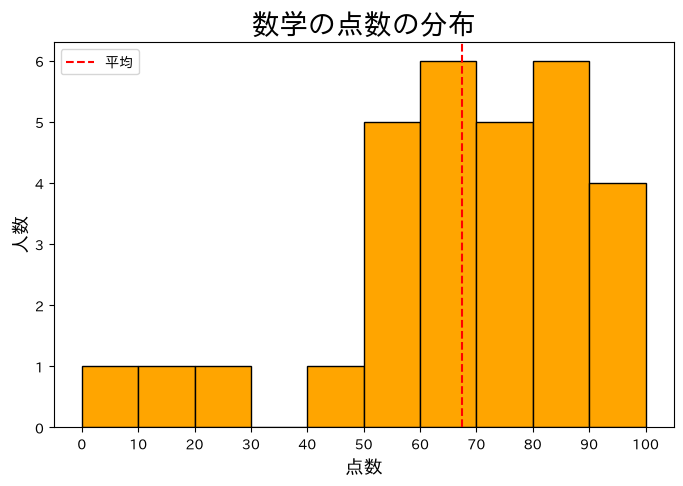

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')  # Excel を読む
data = df['数学']  # 列を取り出す

plt.figure(figsize=(8, 5))  # [0] グラフの大きさ
plt.hist(data, bins=10, range=(0, 100), color='orange', edgecolor='k')  # [1] ヒストグラム [2] 区切りの数 [3] 区切りの範囲 [4] 色と枠線
plt.axvline(x=np.mean(data), color='r', linestyle='--', label='平均')  # [5] 平均の補助線
plt.xticks(range(0, 101, 10))  # [7] 横軸の目盛りを 0, 10, …, 100 に
plt.title('数学の点数の分布', fontsize=20)  # [7] タイトル
plt.xlabel('点数', fontsize=14)  # [7] 横軸の名前
plt.ylabel('人数', fontsize=14)  # [7] 縦軸の名前
plt.legend()  # [7] 凡例
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- 列：`df['数学']` → `df['社会']`、`df['英語']`（タイトルも直す）
- 区切りの数：`bins=10` → `bins=5`（20点刻み）、`bins=20`（5点刻み）
- `, range=(0, 100)` を消すと、区切りの位置がどうなるか
- 色：`'orange'` → `'skyblue'`、`'pink'`
- `, edgecolor='k'` を消すと、棒の区切りがどう見えるか

In [3]:
# 上のコードを貼り付けて、値を変えてみよう

| 番号 | 部品 | 書き方 | 学ぶところ | 演習 |
|---|---|---|---|---|
| [0] | グラフの大きさ（基本設定） | `plt.figure(figsize=(8, 5))` | 第３講 | （どの問題でも書いてよい） |
| [1] | ヒストグラムを描く | `plt.hist(データ)` | AA-1 | （ひな形） |
| [2] | 区切りの数 | `bins=10` | AA-2 | `hist_第９講1` |
| [3] | 区切りの範囲 | `range=(0, 100)` | AA-4 | `hist_第９講2` |
| [4] | 色と枠線 | `color='orange'`、`edgecolor='k'` | AA-3 | `hist_第９講1` |
| [5] | 平均の補助線 | `plt.axvline(x=np.mean(データ))` | AA-5 | `hist_第９講2` |
| [6] | 2つのグループを重ねる | `plt.hist` を2回、`alpha=0.5` | AA-6 | `hist_描画基礎005` |
| [7] | 目盛り・タイトル・軸の名前・凡例 | `plt.xticks`、`plt.title` など | 第３講・AA-4 | （書いてもよい。`hist_第９講2` では凡例が必要） |
| | 重ねずに並べる | `plt.hist([データ1, データ2])` | AC-2（発展） | `hist_描画基礎006` |

- 演習では、**問題で指定されたものだけ**書く（完成形をそのまま貼らない）
- 演習のひな形は、`'Histogram'` などの英語で書かれている。英語のままでよい

## AA-1 ヒストグラムの基本：まず手で数えてみる

例は、小波秀雄『[統計学入門](https://create.niigata-u.ac.jp/public/lectures/dsg/01_chap01.pdf)』第1章の**男子高校生100人の体重**（表1.1）。`dsa2026data.xlsx` の `weight` シートに入っている。

**[1] データを見る**：いちばん軽い人は 43.6 kg、いちばん重い人は 64.6 kg

**[2] 区間を決める**：43〜65 kg を **2 kg ずつ**に分ける → 43〜45、45〜47、…、63〜65 の **11区間**

**[3] 区間ごとに人数を数える**（表1.2）

| 区間 (kg) | 43〜45 | 45〜47 | 47〜49 | 49〜51 | 51〜53 | 53〜55 | 55〜57 | 57〜59 | 59〜61 | 61〜63 | 63〜65 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 人数 | 1 | 3 | 6 | 9 | 21 | 12 | 19 | 15 | 10 | 2 | 2 |

- 区間の境目ちょうどの値は、**右側の区間**に入れる。たとえば 49.0 kg の2人は「47〜49」ではなく「49〜51」で数える（いちばん右の区間だけは、右端の 65 も含む）

**[4] 数えた人数を、すき間のない棒にする**（図1.4）

[3] の数えるところは、`plt.hist` が代わりにやってくれる。`bins=11` が [2] の「11区間」、`range=(43, 65)` が「43〜65 kg」にあたる。

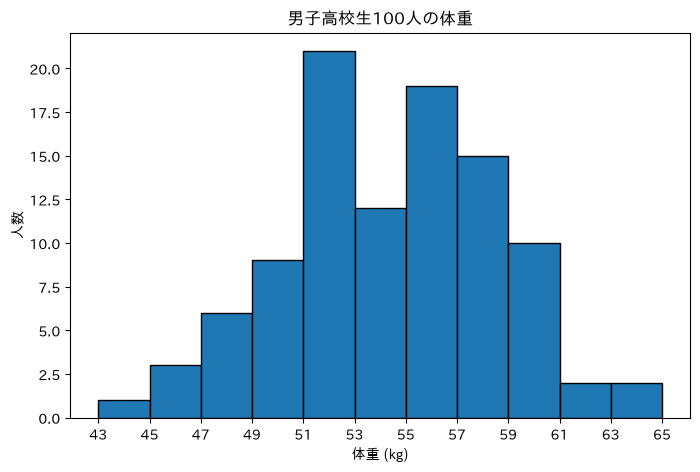

In [4]:
df_weight = pd.read_excel('dsa2026data.xlsx', sheet_name='weight')

plt.figure(figsize=(8, 5))
plt.hist(df_weight['体重'], bins=11, range=(43, 65), edgecolor='k')
plt.xticks(range(43, 66, 2))
plt.title('男子高校生100人の体重')
plt.xlabel('体重 (kg)')
plt.ylabel('人数')
plt.show()

- 棒の高さが [3] の表の人数と同じになっていることを確かめよう（51〜53 kg が 21人でいちばん多い）
- `plt.xticks(range(43, 66, 2))` は、横軸の目盛りを区間の境目（43, 45, …, 65）にする
- matplotlib も、境目ちょうどの値は右側の区間に入れる。だから表1.2 と同じ人数になる

### 演習のひな形

演習「第９講」では、30人の点数のリスト `score` を使う。区間の決め方を書かないと、matplotlib が**データの最小値から最大値まで**を自動で10等分する。


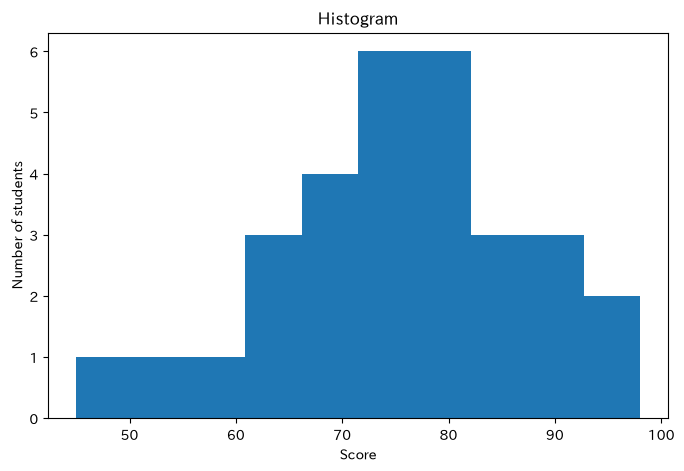

In [5]:
score = [45, 52, 58, 61, 63, 65, 67, 68, 70, 71, 72, 73, 74, 75, 75,
         76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 88, 90, 92, 95, 98]

plt.figure(figsize=(8, 5))
plt.hist(score)
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

- 区切りは 45〜98 点を10等分した半端な値（50.3、55.6 …）になる。0〜100 点を10点刻みにする方法は AA-4
- これが演習「第９講」のひな形

## AA-2 区切りの数

- `bins=` で**区間の数**を決める（bin＝箱）。何も書かないと `10`
- 少なすぎると形が分からず、多すぎるとガタガタになる。データの数が30くらいなら 5〜10 が目安

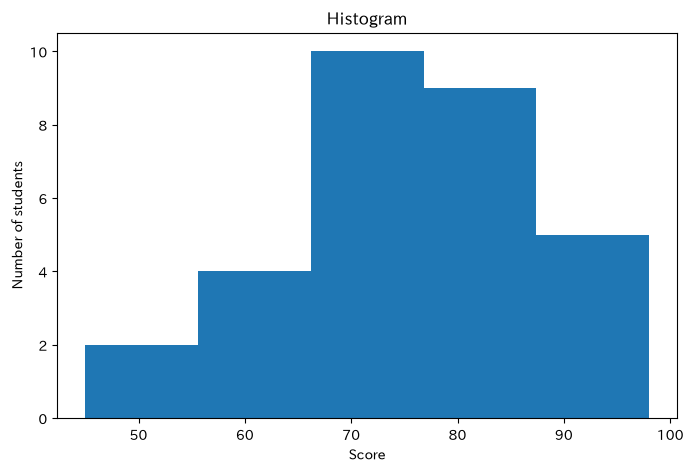

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=5)
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

## AA-3 色と枠線

- 棒グラフと同じく `color=`、`edgecolor=`。ヒストグラムは棒がくっついているので、**枠線を付けると区切りが見やすい**

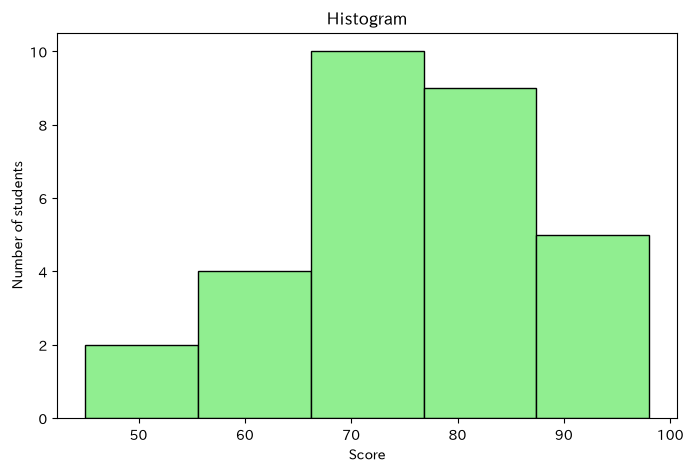

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=5, color='lightgreen', edgecolor='k')
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

- 上の図は、棒の区切りと横軸の数字がずれて見える。2つは別々に決まるため
  - 棒の区切り：データの最小値 45 点から最大値 98 点までを `bins=5` で5等分した **45、55.6、66.2、76.8、87.4、98**（1区間 10.6 点）
  - 横軸の数字：matplotlib が区切りとは関係なく、切りのよい値（50、60、70 …）を自動で並べたもの
- 区切りと数字を揃える方法は、次の AA-4

▶ **演習**：`hist_第９講1`（区切りの数と、色・枠線）

## AA-4 区切りの範囲

- 何も書かないと、区間は**データの最小値から最大値まで**になる（上の図は 45〜98 点）。区切りが 55.6 点のような半端な値になる
- `range=(0, 100)` と書くと 0〜100 点を区切る。`bins=10` と合わせると、**10点刻み**（0〜10, 10〜20, …）になる
- `(0, 100)` のように ( ) で値を組にしたものを**タプル**という。`figsize=(8, 5)` と同じ書き方。`[0, 100]` とリストで書いても動くが、この授業では ( ) で書く

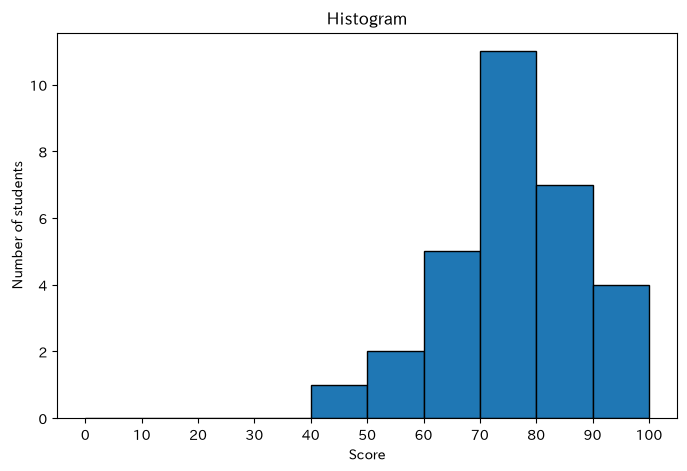

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=10, range=(0, 100), edgecolor='k')
plt.xticks(range(0, 101, 10))
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

- `plt.xticks(range(0, 101, 10))` は、横軸の目盛りを 0, 10, 20, …, 100 にする（なくてもよい）
- 名前は同じ range だが、別のもの。`range=(0, 100)`（= あり）は `plt.hist` の**区切りの範囲**の指定、`range(0, 101, 10)`（= なし）は 0 から 10 おきに数を並べる **Python の命令**（最後の 101 は含まないので、100 まで並ぶ）
- 10点刻みのように切りのよい値にならないときの目盛りの揃え方は、発展の AC-1

## AA-5 平均の補助線

- ヒストグラムでは点数が**横軸**にあるので、平均は**縦の線** `plt.axvline(x=np.mean(データ))`（第６講 N-7 の横棒グラフのときと同じ）

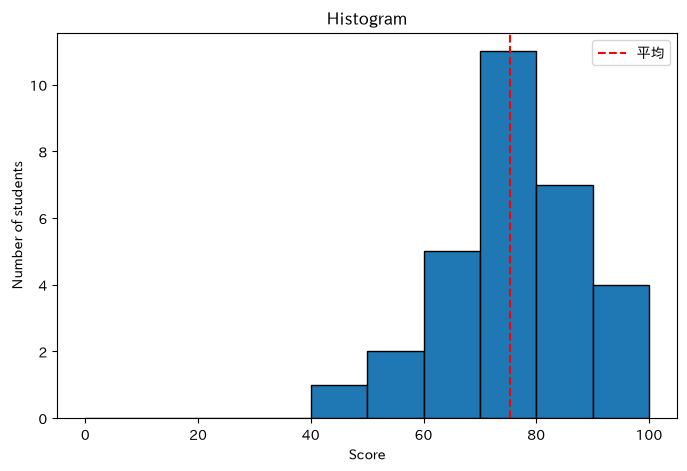

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=10, range=(0, 100), edgecolor='k')
plt.axvline(x=np.mean(score), color='r', linestyle='--', label='平均')
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.legend()
plt.show()

▶ **演習**：`hist_第９講2`（0〜100点の10点刻みと、平均の補助線）

## AA-6 2つのグループを重ねる

- 第４講の散布図と同じく、`plt.hist` を**2回**書くと重なる
- 後ろが隠れないように `alpha=0.5`（透明度）、どちらがどちらか分かるように `label=` と `plt.legend()`
- 2つの `bins=` と `range=` は**同じ値**にする（区間がずれると比べられない）

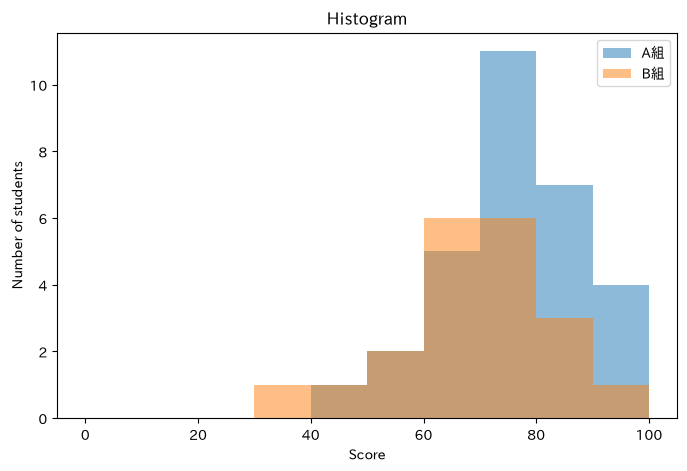

In [10]:
score_b = [38, 47, 55, 58, 60, 62, 64, 66, 67, 69,
           70, 71, 72, 74, 76, 78, 80, 83, 87, 91]

plt.figure(figsize=(8, 5))
plt.hist(score, bins=10, range=(0, 100), alpha=0.5, label='A組')
plt.hist(score_b, bins=10, range=(0, 100), alpha=0.5, label='B組')
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.legend()
plt.show()

▶ **演習**：`hist_描画基礎005`（A組とB組を重ねる）

### 使ってみよう
- `exam` シートの `'数学'` と `'社会'` のヒストグラムを、上のように重ねてみよう。平均は近いのに、分布の形はかなり違う

In [11]:
df_exam = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')

# ここで試してみよう

---
# AB. エラーバー

## AB-0 今日の完成形（エラーバー）

5教科の**平均点**を点で、**平均 ± 標準偏差**を上下の線（エラーバー）で示したもの。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**色や大きさを変えて**、グラフのどこが変わるかを確かめる
1. そのあと部品（[1]〜[3]）の働きを1つずつ学ぶ（AB-1〜AB-5）

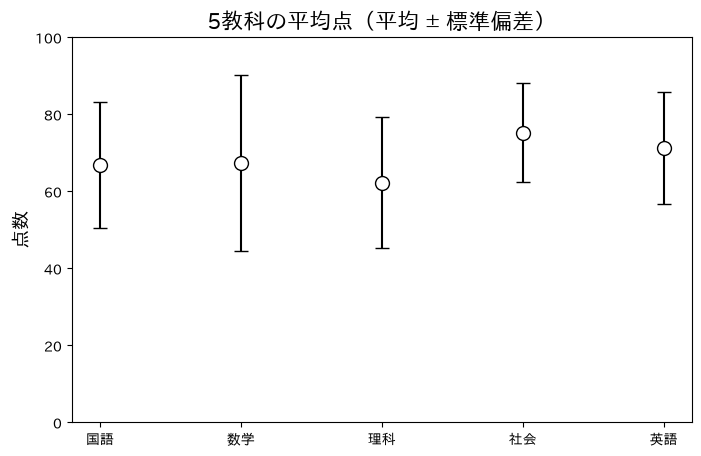

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
subjects = ['国語', '数学', '理科', '社会', '英語']

means = [np.mean(df['国語']), np.mean(df['数学']), np.mean(df['理科']),  # [1] 平均のリスト
         np.mean(df['社会']), np.mean(df['英語'])]
stds = [np.std(df['国語']), np.std(df['数学']), np.std(df['理科']),  # [1] 標準偏差のリスト
        np.std(df['社会']), np.std(df['英語'])]

plt.figure(figsize=(8, 5))
plt.errorbar(subjects, means, yerr=stds,  # [2] エラーバー
             fmt='o', markersize=10, capsize=5,  # [3] 見た目
             color='w', markeredgecolor='k', ecolor='k')
plt.ylim(0, 100)
plt.title('5教科の平均点（平均 ± 標準偏差）', fontsize=16)
plt.ylabel('点数', fontsize=14)
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- `capsize=5` → `capsize=15`、`0`（線の端の横棒の長さ）
- `fmt='o'` → `fmt='s'`（四角）、`fmt='o-'`（点を線でつなぐ）
- `color='w'` → `color='orange'`（点の中の色）

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [1] | 平均・標準偏差のリスト | `[np.mean(df['国語']), np.mean(df['数学']), …]` | AB-3・AB-5 |
| [2] | エラーバー | `plt.errorbar(x, 平均, yerr=標準偏差)` | AB-4 |
| [3] | 見た目 | `fmt`、`markersize`、`capsize`、`color`、`markeredgecolor`、`ecolor` | AB-4 |

In [13]:
# 上のコードを貼り付けて、値を変えてみよう

## AB-1 平均だけでは分からないこと

**エラーバー**は、平均とばらつきを**点1つと縦の線1本**で表したもの。いくつかのグループ（クラス、教科など）の平均とばらつきを並べて比べるときに使う。

- 下の2クラスは、**平均が同じ**（68点）。でも、点数の散らばり方は同じとは限らない
- 散らばりの大きさを1つの数で表したものが**標準偏差**（第４講 G-3）


In [14]:
group1 = [66, 68, 70, 67, 69, 68, 71, 65, 70, 66]
group2 = [40, 95, 55, 85, 60, 90, 45, 80, 52, 78]
m = [np.mean(group1), np.mean(group2)]
s = [np.std(group1), np.std(group2)]
print('平均', m)
print('標準偏差', s)

平均 [np.float64(68.0), np.float64(68.0)]
標準偏差 [np.float64(1.8973665961010275), np.float64(18.83613548475377)]


- まず、一人ひとりの点数を散布図で描く。横の位置は、クラスの名前を人数分（10個）並べたリスト
- `['1組'] * 10` は「`'1組'` を10個並べたリスト」という意味（リストに `* 数` を付けると、その数だけくり返して並べる）


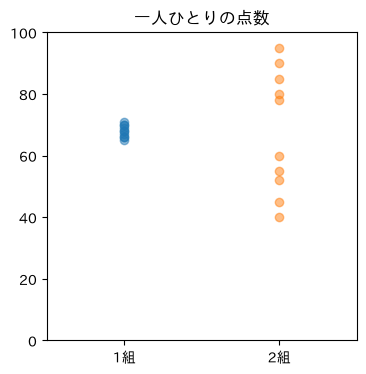

In [15]:
plt.figure(figsize=(4, 4))
plt.scatter(['1組'] * 10, group1, alpha=0.5)
plt.scatter(['2組'] * 10, group2, alpha=0.5)
plt.xlim(-0.5, 1.5)
plt.ylim(0, 100)
plt.title('一人ひとりの点数')
plt.show()

- 同じデータを、平均 ± 標準偏差の**エラーバー**で描く（書き方は AB-4）


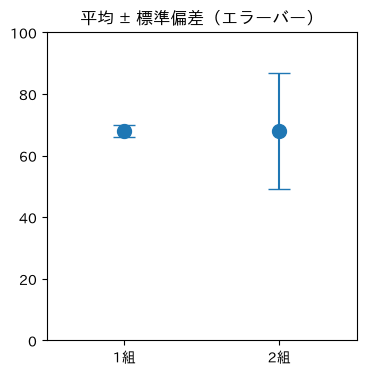

In [16]:
plt.figure(figsize=(4, 4))
plt.errorbar(['1組', '2組'], m, yerr=s, fmt='o', capsize=8, markersize=10)
plt.xlim(-0.5, 1.5)
plt.ylim(0, 100)
plt.title('平均 ± 標準偏差（エラーバー）')
plt.show()

- エラーバーは、平均の点から上下に**標準偏差**の長さの線を引いたもの
- 平均が同じでも、ばらつきが大きいとエラーバーが**長く**（2組）、小さいと**短く**（1組）なる
- 多くのデータでは、エラーバーの範囲（平均 ± 標準偏差）に**全体のおよそ3分の2**の人が入る
- 論文などでは、エラーバーが標準偏差なのか別のもの（AC-4 の標準誤差など）なのかを、必ず図の説明に書く


## AB-2 リストを np.array にする

- 演習「第９講」では、リストを `np.array(リスト)` で **np.array**（numpy の配列）に変えて使う
- np.array にすると、`変数.mean()` や `変数.std()` で平均・標準偏差が求められる（`np.mean(変数)` と同じ結果）

- 2クラス（各100人）の、同じ教科のテストの点数（演習「第９講」と同じデータ）

In [17]:
classA_score = [77,69,63,48,66,65,69,72,67,72,71,63,77,66,64,61,57,58,65,64,72,66,67,
                65,64,75,85,73,66,61,71,49,67,76,61,51,66,67,65,52,76,72,73,58,78,58,
                60,52,57,73,63,69,81,67,64,61,60,58,75,48,66,67,59,67,58,78,88,64,69,
                80,72,72,84,75,57,77,80,63,69,54,57,68,64,64,52,66,74,75,65,79,72,66,
                77,68,52,63,59,77,71,68]

classB_score = [57,76,75,62,66,57,70,67,78,67,55,72,79,61,56,76,72,69,71,76,69,71,73,
                67,67,71,58,65,74,69,77,74,75,77,65,73,84,66,63,53,56,71,63,63,68,70,
                77,69,73,62,64,57,79,79,64,57,66,83,64,61,68,57,48,69,67,57,58,71,73,
                74,68,56,71,58,63,80,67,60,68,67,55,59,51,63,71,75,71,61,95,67,71,68,
                72,61,67,73,60,65,81,64]

In [18]:
classA_score_np = np.array(classA_score)
classB_score_np = np.array(classB_score)

print(classA_score_np)
print(classB_score_np)

[77 69 63 48 66 65 69 72 67 72 71 63 77 66 64 61 57 58 65 64 72 66 67 65
 64 75 85 73 66 61 71 49 67 76 61 51 66 67 65 52 76 72 73 58 78 58 60 52
 57 73 63 69 81 67 64 61 60 58 75 48 66 67 59 67 58 78 88 64 69 80 72 72
 84 75 57 77 80 63 69 54 57 68 64 64 52 66 74 75 65 79 72 66 77 68 52 63
 59 77 71 68]
[57 76 75 62 66 57 70 67 78 67 55 72 79 61 56 76 72 69 71 76 69 71 73 67
 67 71 58 65 74 69 77 74 75 77 65 73 84 66 63 53 56 71 63 63 68 70 77 69
 73 62 64 57 79 79 64 57 66 83 64 61 68 57 48 69 67 57 58 71 73 74 68 56
 71 58 63 80 67 60 68 67 55 59 51 63 71 75 71 61 95 67 71 68 72 61 67 73
 60 65 81 64]


- リストは `[77, 69, 63, …]` と `,` 区切りで、np.array は `[77 69 63 …]` と空白区切りで表示される

▶ **演習**：`errorbar01`

- 演習 `errorbar02` は、classA と classB の**ヒストグラムを重ねる**問題。AA-6 と同じ書き方で描ける（`alpha=`、`label=`、`plt.legend()`）

▶ **演習**：`errorbar02`

## AB-3 平均と標準偏差を求める

In [19]:
mean_A = classA_score_np.mean()
std_A = classA_score_np.std()
mean_B = classB_score_np.mean()
std_B = classB_score_np.std()

print('classA 平均', mean_A, '標準偏差', std_A)
print('classB 平均', mean_B, '標準偏差', std_B)

classA 平均 66.72 標準偏差 8.369085971598093
classB 平均 67.49 標準偏差 7.963033341635584


- `np.mean(classA_score)` と `np.std(classA_score)` でも同じ値になる（リストのままでもよい）

▶ **演習**：`errorbar03`

## AB-4 エラーバーを描く

- `plt.errorbar(横の位置, 平均, yerr=エラーバーの長さ)` で描く。横の位置・平均・長さは、**同じ個数のリスト**にする
- `fmt='o'` で、点だけを描く（何も書かないと、点が線でつながる）
- 見た目のオプション：`markersize`（点の大きさ）、`capsize`（線の端の横棒の長さ）、`color`（点の中の色）、`markeredgecolor`（点のふちの色）、`ecolor`（線の色）

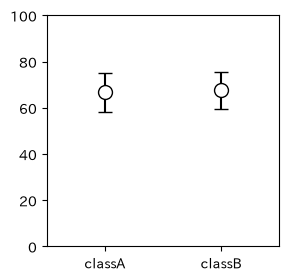

In [20]:
myclass = ['classA', 'classB']
mean_score = [mean_A, mean_B]
errorbar = [std_A, std_B]

plt.figure(figsize=(3, 3))
plt.errorbar(myclass, mean_score, yerr=errorbar, fmt='o', capsize=5, markersize=10,
             color='w', markeredgecolor='k', ecolor='k')
plt.xlim(-0.5, 1.5)
plt.ylim(0, 100)
plt.show()

- 横軸が文字（`'classA'` など）のとき、位置は左から `0, 1` になる。`plt.xlim(-0.5, 1.5)` で左右に余白を作っている

▶ **演習**：`errorbar04`（6つのオプションを全部使う）
▶ **演習**：`errorbar05`（一人ひとりの点の上にエラーバーを重ねる。AB-1 の散布図と同じ書き方）

## AB-5 5教科のエラーバー

- `exam` シートの5教科で、教科ごとに平均と標準偏差を計算し、リストにまとめる（AB-0 の [1]）
- 5教科なので、`np.mean` と `np.std` を5回ずつ書く。同じ処理をくり返す書き方（for 文）は、第12講で学ぶ
- `(` や `[` の中なら、`,` の後ろで改行して次の行に続けて書ける

[np.float64(66.76666666666667), np.float64(67.36666666666666), np.float64(62.233333333333334), np.float64(75.23333333333333), np.float64(71.36666666666666)]
[np.float64(16.3354080314988), np.float64(22.77642543410962), np.float64(17.03659459973018), np.float64(12.914290103946437), np.float64(14.554457125644442)]


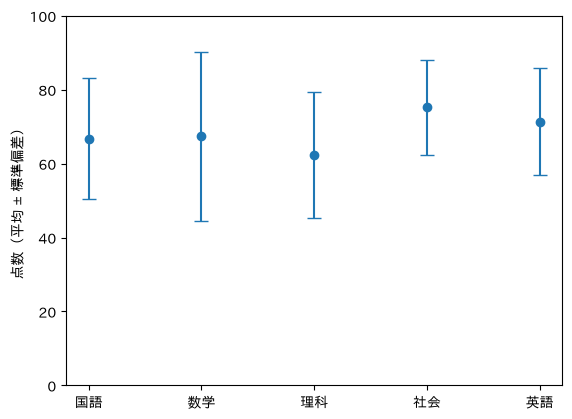

In [21]:
df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
subjects = ['国語', '数学', '理科', '社会', '英語']

means = [np.mean(df['国語']), np.mean(df['数学']), np.mean(df['理科']),
         np.mean(df['社会']), np.mean(df['英語'])]
stds = [np.std(df['国語']), np.std(df['数学']), np.std(df['理科']),
        np.std(df['社会']), np.std(df['英語'])]
print(means)
print(stds)

plt.errorbar(subjects, means, yerr=stds, fmt='o', capsize=5)
plt.ylim(0, 100)
plt.ylabel('点数（平均 ± 標準偏差）')
plt.show()

- 数学はエラーバーが長い＝点数のばらつきが大きい（第７講の箱ひげ図でも、数学の箱は長かった）

## AB-6 棒グラフにエラーバーを付ける

- 棒グラフでは、`plt.bar(…, yerr=標準偏差, capsize=5)` と書くだけでエラーバーが付く

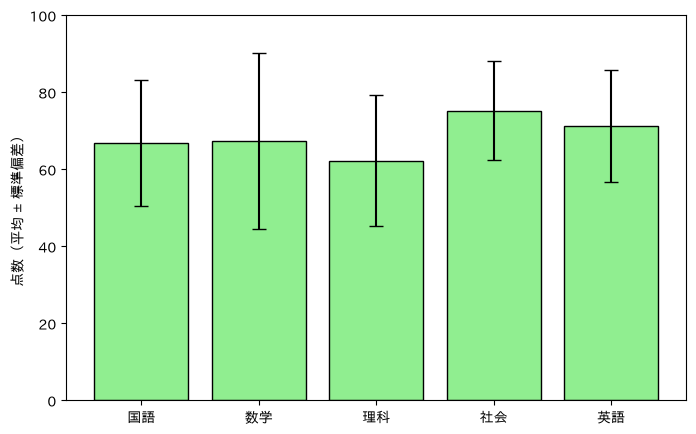

In [22]:
plt.figure(figsize=(8, 5))
plt.bar(subjects, means, yerr=stds, capsize=5, color='lightgreen', edgecolor='k')
plt.ylim(0, 100)
plt.ylabel('点数（平均 ± 標準偏差）')
plt.show()

### 使ってみよう
- AB-3 で求めた classA・classB の平均（`mean_A`、`mean_B`）と標準偏差（`std_A`、`std_B`）で、棒グラフにエラーバーを付けてみよう
- 棒の色は `color=['lightcoral', 'lightblue']` のように、リストで1本ずつ変えられる（第６講）

In [23]:
# ここで試してみよう

---
# AC. 発展（できる人だけ）

ここは授業の本編ではない。課題に使わなくても困らない。

## AC-1 区切りを15点刻みにする

- 10点刻みのように切りのよい値にならないときも、考え方は同じ。**1区間の幅 ＝（終わり − 始め）÷ `bins`** を計算して、その幅で目盛りを並べる
- 下の例は 40〜100 点を4つに分ける。幅は (100 − 40) ÷ 4 = **15点**なので、目盛りは `range(40, 101, 15)` で 40, 55, 70, 85, 100
- 幅が 12.5 点のように小数になると `range()` では並べられない（`range()` は整数だけ）。割り切れる `bins` を選ぶとよい

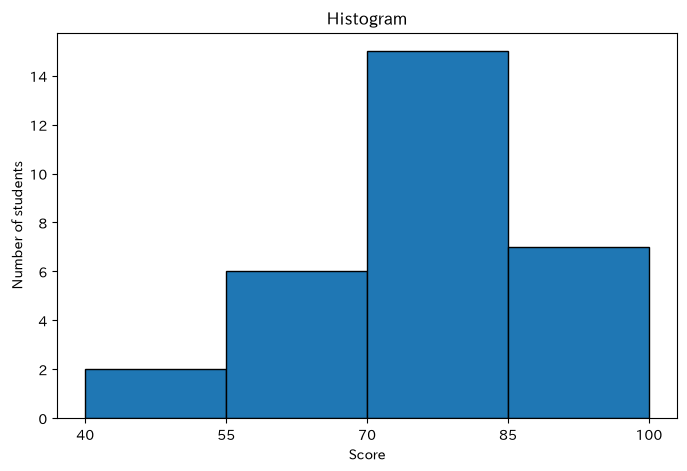

In [24]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=4, range=(40, 100), edgecolor='k')  # 40〜100点を4つに分ける → 15点刻み
plt.xticks(range(40, 101, 15))  # 目盛りも15点刻み：40, 55, 70, 85, 100
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

▶ **演習**（発展）：`hist_第９講3`（15点刻みで、目盛りを棒の区切りと揃える）

## AC-2 ヒストグラムを並べる・横向きにする

- `plt.hist([データ1, データ2])` のように**リストにまとめて**渡すと、重ねずに**横に並べて**描く。`label=` もリストで渡す

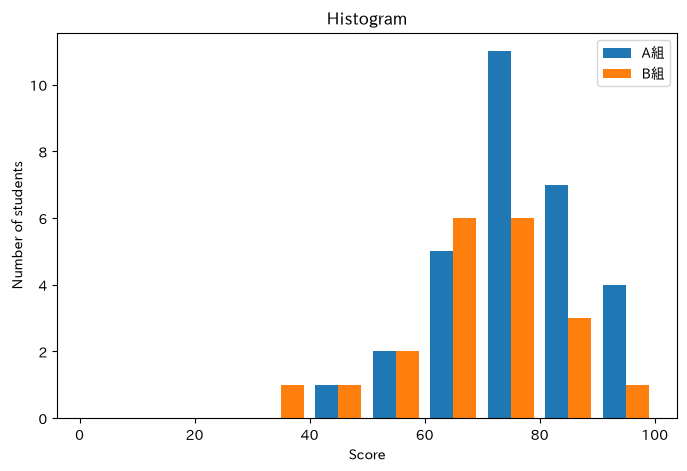

In [25]:
plt.figure(figsize=(8, 5))
plt.hist([score, score_b], bins=10, range=(0, 100), label=['A組', 'B組'])
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.legend()
plt.show()

▶ **演習**（発展）：`hist_描画基礎006`

- `orientation='horizontal'` で横向きになる。横棒グラフ（第６講 N-7）と同じく `xlabel` と `ylabel` を入れ替え、平均の線は**横の線** `plt.axhline`

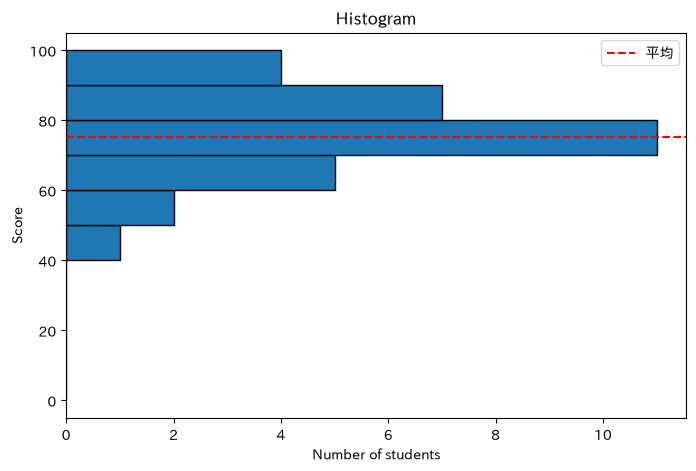

In [26]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=10, range=(0, 100), edgecolor='k', orientation='horizontal')
plt.axhline(y=np.mean(score), color='r', linestyle='--', label='平均')
plt.title('Histogram')
plt.xlabel('Number of students')
plt.ylabel('Score')
plt.legend()
plt.show()

▶ 横向きの問題は、演習「第９講」の `hist_描画基礎007`（発展）

## AC-3 ヒストグラムの1本だけ色を変える

- 棒グラフ（第６講 P-4）では `color=` に色のリストを渡せたが、`plt.hist` の `color=` は**全部の棒に同じ色**しか付けられない
- そこで、描いた棒をあとから1本取り出して色を塗り替える
- `plt.hist` は描いた結果を**3つ**返す。`n, bins, patches = plt.hist(...)` のように、`,` で区切った3つの変数で受け取る
  - `n`：各区間の人数
  - `bins`：区切りの位置
  - `patches`：棒（左から順に入っている）
- `patches` はリストと同じく先頭が `[0]`。10点刻みなら 0〜10点が `[0]`、10〜20点が `[1]` … 70〜80点が `[7]`
- `patches[7].set_facecolor('r')` で、その棒だけ色が変わる（`facecolor` は塗りの色。枠線の色は `edgecolor`）

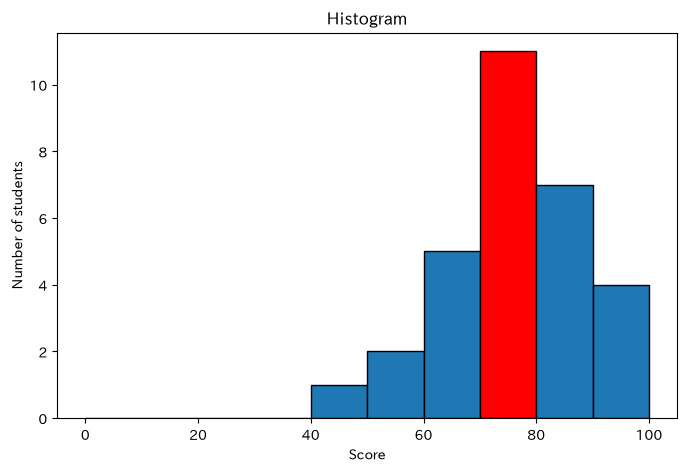

In [27]:
plt.figure(figsize=(8, 5))
n, bins, patches = plt.hist(score, bins=10, range=(0, 100), edgecolor='k')
patches[7].set_facecolor('r')  # 左から8本目（70〜80点）だけ赤
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

▶ **演習**（発展）：`hist_第９講4`（人数が最も多い区間の棒だけ赤にする）

---
# AC. 発展（できる人だけ）

## AC-4 標準誤差と信頼区間

- **標準偏差**：一人ひとりの点数のばらつき
- **標準誤差** ＝ 標準偏差 ÷ √人数：**平均値そのもの**のぶれ（もう一度同じ人数でテストをしたら、平均はどれくらい変わりそうか）。人数が多いほど小さくなる
- 平均 ± 1.96 × 標準誤差 が、おおよそ **95% 信頼区間**

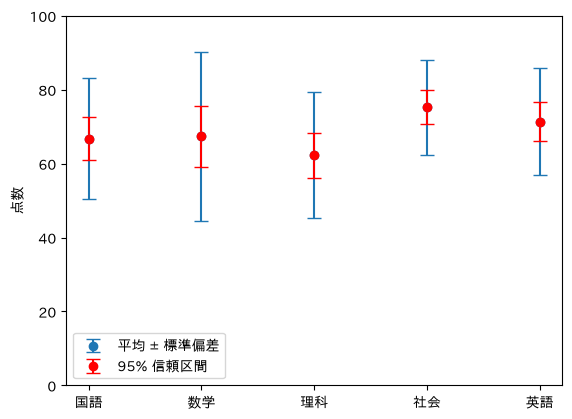

In [28]:
n = len(df)
ses = 1.96 * np.array(stds) / np.sqrt(n)

plt.errorbar(subjects, means, yerr=stds, fmt='o', capsize=5, label='平均 ± 標準偏差')
plt.errorbar(subjects, means, yerr=ses, fmt='o', capsize=5, color='r', label='95% 信頼区間')
plt.ylim(0, 100)
plt.ylabel('点数')
plt.legend()
plt.show()

- `np.array(stds)` にすると、`1.96 * …` や `/ np.sqrt(n)` が5教科ぶん**まとめて**計算される（リストのままではできない）
- 信頼区間は標準偏差より短い。2つの教科の信頼区間が重なっていなければ、「平均点に差がある」と考える目安になる

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| **以下はヒストグラム** | |
| ヒストグラム | `plt.hist(データ)` |
| 区間の数・範囲 | `bins=10`、`range=(0, 100)` |
| 色・枠線 | `color='lightgreen'`、`edgecolor='k'` |
| 平均の補助線 | `plt.axvline(x=np.mean(データ))` |
| 2つのグループを重ねる | `plt.hist` を2回、`alpha=0.5`、`label=` と `plt.legend()` |
| **以下はエラーバー** | |
| np.array にする | `np.array(リスト)`。平均は `変数.mean()`、標準偏差は `変数.std()` |
| エラーバー | `plt.errorbar(x, 平均のリスト, yerr=標準偏差のリスト, fmt='o', capsize=5)` |
| 見た目 | `markersize=10`、`color='w'`、`markeredgecolor='k'`、`ecolor='k'` |
| 棒グラフに付ける | `plt.bar(x, 平均のリスト, yerr=標準偏差のリスト, capsize=5)` |

- ヒストグラムは**1つの量の分布**、箱ひげ図は**いくつかのグループのばらつき比べ**、エラーバーは**平均とばらつき**を並べて比べるときに使う

次回（第10講）は、**遊び心のあるグラフ・グラフを並べる**。最後に**第２回課題**を出題する。